# CNN Experiment
- **Group Name**: MVPs
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
- **Owner:** Bryan Jacome
---


Text CNN trained from scratch on the shared Enron partitions, with three seeds, plus one ablation (every kernel width set to 1).

**Question this notebook answers:** does a convolutional model that reads *local word patterns* (a few neighbouring words at a time) classify spam better than the same model restricted to *one word at a time*?

Every configuration is chosen on the validation split. The test split is scored once, in Section 7, for the frozen final models only.

Model code: `src/cnn_model.py`. Evaluation and inference-cost code are shared with the Transformer (`src/transformer_model.py`), so all models are measured the same way.

## 1. Initial Configuration


### 1.1. Imports, Paths, and Device


In [1]:
# Import required libraries
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn

# Locate the repository from either its root or the notebooks folder
current_dir = Path.cwd().resolve()
PROJECT_ROOT = current_dir if (current_dir / 'src').is_dir() else current_dir.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise FileNotFoundError('Place this notebook in the repository notebooks folder.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import shared project modules
from src.config import BATCH_SIZE, TRAINING_SEEDS
from src.data import load_prepared_data
from src.reproducibility import set_seed
from src.text import EncodedTextDataset, make_data_loader

# Use CUDA when it is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Print the runtime and selected device
print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

d:\Humber\Advanced Deep Learning\Repos\AIGC5500-Midterm-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.10
Interpreter: d:\Humber\Advanced Deep Learning\Repos\AIGC5500-Midterm-Project\.venv\Scripts\python.exe
PyTorch: 2.9.1+cu126
Device: cuda
GPU: NVIDIA GeForce GTX 1050 Ti


### 1.2. Experiment Configuration


In [2]:
# Name this experiment and its owner
MODEL_NAME = 'cnn'
OWNER = 'Bryan Jacome'

# Reset randomness before the first run
set_seed(TRAINING_SEEDS[0])

# Point to the shared prepared data and this model's output folders
PREPARED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'enron'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'enron' / MODEL_NAME
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints' / 'enron' / MODEL_NAME

# Show the shared training seeds and batch size
print('Training seeds:', TRAINING_SEEDS)
print('Batch size:', BATCH_SIZE)

Training seeds: (42, 123, 2026)
Batch size: 64


## 2. Load Shared Prepared Data


Run `01_data_preparation.ipynb` once before this notebook. The saved preprocessing metadata controls sequence length; this notebook does not refit the vocabulary.


In [3]:
# Load the shared splits, vocabulary and settings saved by 01_data_preparation
prepared = load_prepared_data(PREPARED_DATA_DIR)
splits = prepared['splits']
vocabulary = prepared['vocabulary']
metadata = prepared['metadata']
MAX_LENGTH = metadata['max_length']

# Check the data is exactly what was saved
assert len(vocabulary) == metadata['vocabulary_size']
assert vocabulary['<pad>'] == 0 and vocabulary['<unk>'] == 1
for name, expected_size in metadata['split_sizes'].items():
    assert len(splits[name]) == expected_size

pd.DataFrame([{'split': name, 'rows': len(part)} for name, part in splits.items()])

,split,rows
0,train,22524
1,validation,5632
2,test,1981


In [4]:
# Print dataset information
print('Vocabulary size:', len(vocabulary))
print('Maximum length:', MAX_LENGTH)
print('Dataset:', metadata['dataset_id'])
print('Dataset revision:', metadata['dataset_revision'])

Vocabulary size: 10000
Maximum length: 256
Dataset: SetFit/enron_spam
Dataset revision: main


### 2.1. Encode Development Partitions


Only training and validation are encoded. Recreate the training loader for each seed; keep validation order fixed.


In [5]:
# Encode train and validation only
encoded_datasets = {
    name: EncodedTextDataset(
        texts = splits[name]['text'],
        labels = splits[name]['label'],
        vocabulary = vocabulary,
        max_length = MAX_LENGTH) for name in ('train', 'validation')
    }
# Keep validation order fixed
validation_loader = make_data_loader(
    encoded_datasets['validation'], batch_size = BATCH_SIZE, shuffle = False, seed = TRAINING_SEEDS[0])

# Inspect one validation batch
example_batch = next(iter(validation_loader))
for name, tensor in example_batch.items():
    print(name, tuple(tensor.shape))

# Recreate the training loader inside every seeded run, before training.
# Do not encode or evaluate the test partition during development.

tokens (64, 256)
lengths (64,)
labels (64,)


## 3. Model, Settings, and Ablation

The CNN turns each word into a 64-number vector, slides 100 filters of each width (3, 5 and 7 words) along the email, keeps each filter's strongest match, and classifies from those scores.

**Ablation:** all widths set to 1, so the model sees one word at a time and cannot detect multi-word patterns. Everything else stays the same.

In [ ]:
# Model and training loop: src/cnn_model.py. Evaluation and cost functions are shared with the Transformer.
from src.cnn_model import (TextCNN, build_model, count_parameters, evaluate, train_one_run,
                           load_checkpoint, measure_cost, hardware_description)

VOCAB_SIZE = len(vocabulary)   # 10,000: <pad>, <unk> and the 9,998 most frequent training tokens

# Same for both variants (embed_dim matches the Transformer)
MODEL_CONFIG = dict(embed_dim = 64, num_filters = 100, dropout = 0.1)

# Same training budget as every other model: do not change
TRAIN_CONFIG = dict(epochs = 10, lr = 1e-3, weight_decay = 1e-2, grad_clip = 1.0, batch_size = BATCH_SIZE)

# The only difference between the two variants: the window width
VARIANTS = {
    'CNN (full)': dict(kernel_sizes = (3, 5, 7)),
    'Ablation: kernel width 1': dict(kernel_sizes = (1, 1, 1)),
}

# Names for checkpoint files, e.g. 'cnn_full'
VARIANT_SLUG = {name: name.lower().replace(' ', '_').replace(':', '').replace('(', '').replace(')', '') for name in VARIANTS}

print('Model config:', MODEL_CONFIG)
print('Train config:', TRAIN_CONFIG)
print('Hardware:', hardware_description(device))

Model config: {'embed_dim': 64, 'num_filters': 100, 'dropout': 0.1}
Train config: {'epochs': 10, 'lr': 0.001, 'weight_decay': 0.01, 'grad_clip': 1.0, 'batch_size': 64}
Hardware: GPU: NVIDIA GeForce GTX 1050 Ti


In [7]:
# Parameter counts (should be within ~2x of the Transformer's 723,586).
# The ablation is smaller because width-1 filters have fewer weights.
parameter_table = pd.DataFrame({name: {'parameters': count_parameters(build_model(VOCAB_SIZE, MODEL_CONFIG, cfg))}
                                for name, cfg in VARIANTS.items()}).T
parameter_table

,parameters
CNN (full),736902
Ablation: kernel width 1,660102


In [8]:
# Quick check: one batch in, one pair of scores (ham, spam) per email out
check_model = build_model(VOCAB_SIZE, MODEL_CONFIG, VARIANTS['CNN (full)']).to(device)
with torch.no_grad():
    logits = check_model(example_batch['tokens'].to(device))
print('Input tokens:', tuple(example_batch['tokens'].shape), '-> output scores:', tuple(logits.shape))
assert logits.shape == (example_batch['tokens'].shape[0], 2)
del check_model, logits

Input tokens: (64, 256) -> output scores: (64, 2)


## 4. Train on Training Data, Select on Validation Data

Each variant is trained once per seed (6 runs). The epoch with the best validation F1 is kept. The test split is not used here.

In [9]:
RESULTS_DIR.mkdir(parents = True, exist_ok = True)
CHECKPOINT_DIR.mkdir(parents = True, exist_ok = True)

validation_rows, histories = [], {}
for variant, variant_config in VARIANTS.items():
    for seed in TRAINING_SEEDS:
        checkpoint = CHECKPOINT_DIR / f'{VARIANT_SLUG[variant]}_seed{seed}.pt'
        model, history, best_epoch, seconds = train_one_run(
            MODEL_CONFIG, variant_config, seed, encoded_datasets['train'], validation_loader,
            VOCAB_SIZE, device, TRAIN_CONFIG, checkpoint)

        # Record the scores from the best epoch
        best = history.loc[history['epoch'] == best_epoch].iloc[0]
        histories[(variant, seed)] = history
        validation_rows.append({'variant': variant, 'seed': seed, 'best_epoch': best_epoch,
                                'val_accuracy': best['val_accuracy'], 'val_f1': best['val_f1'],
                                'val_loss': best['val_loss'], 'train_seconds': round(seconds, 1)})
        print(f'{variant:26s} seed {seed:5d}  best epoch {best_epoch:2d}  '
              f'val acc {best["val_accuracy"]:.4f}  F1 {best["val_f1"]:.4f}  ({seconds:.0f}s)')

validation_results = pd.DataFrame(validation_rows)
validation_results.to_csv(RESULTS_DIR / 'validation_per_seed.csv', index = False)
validation_results.round(4)

CNN (full)                 seed    42  best epoch  6  val acc 0.9879  F1 0.9874  (82s)
CNN (full)                 seed   123  best epoch  6  val acc 0.9872  F1 0.9868  (82s)
CNN (full)                 seed  2026  best epoch 10  val acc 0.9876  F1 0.9871  (83s)
Ablation: kernel width 1   seed    42  best epoch  7  val acc 0.9893  F1 0.9890  (52s)
Ablation: kernel width 1   seed   123  best epoch  9  val acc 0.9897  F1 0.9894  (52s)
Ablation: kernel width 1   seed  2026  best epoch 10  val acc 0.9895  F1 0.9891  (52s)


,variant,seed,best_epoch,val_accuracy,val_f1,val_loss,train_seconds
0,CNN (full),42,6,0.9879,0.9874,0.0430,81.7
1,CNN (full),123,6,0.9872,0.9868,0.0478,81.7
2,CNN (full),2026,10,0.9876,0.9871,0.0632,82.9
3,Ablation: kernel width 1,42,7,0.9893,0.9890,0.0340,51.8
4,Ablation: kernel width 1,123,9,0.9897,0.9894,0.0341,51.9
5,Ablation: kernel width 1,2026,10,0.9895,0.9891,0.0355,51.7


In [10]:
# Mean and spread over the 3 seeds
validation_summary = validation_results.groupby('variant')[['val_accuracy', 'val_f1']].agg(['mean', 'std'])
validation_summary.round(4)

val_accuracy          val_f1        
                                 mean     std    mean     std
variant                                                      
Ablation: kernel width 1       0.9895  0.0002  0.9892  0.0002
CNN (full)                     0.9876  0.0004  0.9871  0.0003

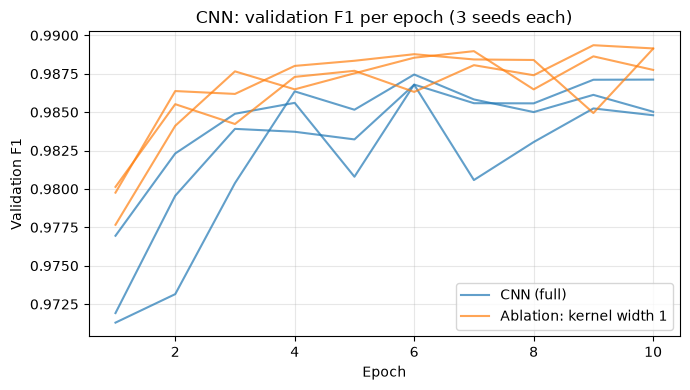

In [11]:
# Validation F1 per epoch, one line per run
fig, ax = plt.subplots(figsize = (7, 4))
colors = {name: color for name, color in zip(VARIANTS, ['tab:blue', 'tab:orange'])}
for (variant, seed), history in histories.items():
    ax.plot(history['epoch'], history['val_f1'], color = colors[variant], alpha = 0.7,
            label = variant if seed == TRAINING_SEEDS[0] else None)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation F1'); ax.set_title('CNN: validation F1 per epoch (3 seeds each)')
ax.legend(); ax.grid(alpha = 0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / 'validation_curves.png', dpi = 150)
plt.show()

In [12]:
# Ablation minus full model, seed by seed (both variants used the same seeds)
pivot = validation_results.pivot(index = 'seed', columns = 'variant', values = 'val_f1')
pivot['difference (ablation - full)'] = pivot['Ablation: kernel width 1'] - pivot['CNN (full)']
display(pivot.round(4))

# A difference smaller than the seed-to-seed spread is not a clear effect
print('Mean difference: %.4f | spread of the full model across seeds (std): %.4f' %
      (pivot['difference (ablation - full)'].mean(), pivot['CNN (full)'].std()))

variant,Ablation: kernel width 1,CNN (full),difference (ablation - full)
seed,,,
42,0.9890,0.9874,0.0015
123,0.9894,0.9868,0.0026
2026,0.9891,0.9871,0.0020


Mean difference: 0.0020 | spread of the full model across seeds (std): 0.0003


**Interpretation:** *(to write from the numbers above: which variant wins, on how many seeds, and whether the gap is larger than the seed-to-seed spread)*

## 5. Inference Cost

Parameters, time per sample and peak memory, measured on the validation split with the seed-42 weights. Compare across models only if they were timed on the same hardware.

In [13]:
cost_rows = []
for variant, variant_config in VARIANTS.items():
    checkpoint = CHECKPOINT_DIR / f'{VARIANT_SLUG[variant]}_seed{TRAINING_SEEDS[0]}.pt'
    model = load_checkpoint(checkpoint, VOCAB_SIZE, MODEL_CONFIG, variant_config, device)
    cost_rows.append({'variant': variant, **measure_cost(model, encoded_datasets['validation'], device, batch_size = BATCH_SIZE)})

cost_results = pd.DataFrame(cost_rows)
cost_results.to_csv(RESULTS_DIR / 'inference_cost.csv', index = False)
cost_results.round(3)

,variant,parameters,ms_per_sample_batch1_mean,ms_per_sample_batch1_median,ms_per_sample_batch64,peak_memory_mb,memory_measure,samples_timed,hardware
0,CNN (full),736902,2.243,1.63,0.098,72.462,CUDA peak allocated (includes weights),300,GPU: NVIDIA GeForce GTX 1050 Ti
1,Ablation: kernel width 1,660102,1.972,1.79,0.058,45.266,CUDA peak allocated (includes weights),300,GPU: NVIDIA GeForce GTX 1050 Ti


## 6. Freeze Before Testing

Confirm with the group that the settings in Section 3 match the other models. Nothing changes after the test result is seen.

## 7. Final Test Evaluation (run once)

In [14]:
TEST_FILE = RESULTS_DIR / 'test_per_seed.csv'
ALLOW_TEST_RERUN = False   # keep False: the test split is scored only once
if TEST_FILE.exists() and not ALLOW_TEST_RERUN:
    raise RuntimeError('Test results already exist. The test split is scored once; do not rerun after seeing it.')

# The only place the test split is encoded
test_dataset = EncodedTextDataset(texts = splits['test']['text'], labels = splits['test']['label'],
                                  vocabulary = vocabulary, max_length = MAX_LENGTH)
test_loader = make_data_loader(test_dataset, batch_size = BATCH_SIZE, shuffle = False, seed = TRAINING_SEEDS[0])

# Score every frozen model once
test_rows = []
for variant, variant_config in VARIANTS.items():
    for seed in TRAINING_SEEDS:
        checkpoint = CHECKPOINT_DIR / f'{VARIANT_SLUG[variant]}_seed{seed}.pt'
        model = load_checkpoint(checkpoint, VOCAB_SIZE, MODEL_CONFIG, variant_config, device)
        result = evaluate(model, test_loader, device)
        test_rows.append({'variant': variant, 'seed': seed, 'test_accuracy': result['accuracy'], 'test_f1': result['f1']})

test_results = pd.DataFrame(test_rows)
test_results.to_csv(TEST_FILE, index = False)
test_results.round(4)

,variant,seed,test_accuracy,test_f1
0,CNN (full),42,0.9889,0.9889
1,CNN (full),123,0.9884,0.9885
2,CNN (full),2026,0.9889,0.9889
3,Ablation: kernel width 1,42,0.9874,0.9874
4,Ablation: kernel width 1,123,0.9859,0.9860
5,Ablation: kernel width 1,2026,0.9894,0.9894


In [15]:
# Mean and spread over the 3 seeds
test_summary = test_results.groupby('variant')[['test_accuracy', 'test_f1']].agg(['mean', 'std'])
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv')
test_summary.round(4)

test_accuracy         test_f1        
                                  mean     std    mean     std
variant                                                       
Ablation: kernel width 1        0.9875  0.0018  0.9876  0.0017
CNN (full)                      0.9887  0.0003  0.9888  0.0002